ASSIGMENT 2ND CHEN Suzanne

In [ ]:
%pip install "scikit-learn==1.9.1" "numpy==2.3.5" "scipy==1.17.0" "pandas==2.2.3" "matplotlib==3.10.8" "nltk==3.10.4" "umap-learn==0.5.12" "spacy==3.8.18" "spacy-lookups-data==1.0.5"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 53.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 34.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 44.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 27.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.5/98.5 MB 24.0 MB/s  0:00:04
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Attempting uninstall: nltk
    Found existing installation: nltk 3.9.1
    Uninstalling nltk-3.9.1:
      Successfully uninstalled nltk-3.9.1
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling s

In [ ]:
from pathlib import Path
from time import perf_counter
import hashlib
import io
import re
import tarfile
import unicodedata
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split


SEED = 2026
N_JOBS = 1  # Conservative memory use; increase only after checking your machine.
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
CLASS_NAMES = ['Negative', 'Positive']  # Explicit mapping: 0, 1.
NEG, POS, INK, MUTED = '#d26936', '#286fb5', '#233247', '#697586'
CLASS_COLORS = [NEG, POS]
MODEL_COLORS = [POS, NEG, '#22856b', '#8060af', '#ad5d87', '#7c7860']


In [ ]:
DATA_URL = 'https://www.cs.cornell.edu/people/pabo/movie-review-data/review_polarity.tar.gz'
ARCHIVE = DATA_DIR / 'review_polarity.tar.gz'
EXPECTED_SHA256 = 'fc0dccc2671af5db3c5d8f81f77a1ebfec953ecdd422334062df61ede36b2179'
if not ARCHIVE.exists():
    try:
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
    except OSError as exc:
        raise RuntimeError('Put the supplied review_polarity.tar.gz in data/ and rerun.') from exc
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Unexpected download checksum.')
    ARCHIVE.write_bytes(payload)
payload = ARCHIVE.read_bytes()


assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA256
print('Verified original Cornell archive:', len(payload), 'bytes')

Verified original Cornell archive: 3127238 bytes


In [ ]:
rows = []
with tarfile.open(fileobj=io.BytesIO(payload), mode='r:gz') as archive:
    for member in sorted(archive.getmembers(), key=lambda item: item.name):
        parts = Path(member.name).parts
        if (member.isfile() and len(parts) == 3 and parts[0] == 'txt_sentoken'
                and parts[1] in {'neg', 'pos'} and parts[2].endswith('.txt')):
            rows.append({'text': archive.extractfile(member).read().decode('utf-8'),
                         'label': int(parts[1] == 'pos'), 'file': member.name})

reviews = pd.DataFrame(rows)
assert reviews.shape[0] == 2000
assert reviews.label.value_counts().sort_index().tolist() == [1000, 1000]
assert reviews.text.str.strip().ne('').all()
dedup_text = reviews.text.str.replace(r'\s+', ' ', regex=True).str.strip()
assert not dedup_text.duplicated().any(), 'Resolve duplicated texts before splitting.'

train, temp = train_test_split(
    reviews, test_size=0.30, stratify=reviews.label, random_state=SEED
)

dev, test = train_test_split(
    temp, test_size=0.50, stratify=temp.label, random_state=SEED
)

train = train.reset_index(drop=True)
dev = dev.reset_index(drop=True)
test = test.reset_index(drop=True)

# Extraction X and y
X_train, y_train = train.text.to_numpy(), train.label.to_numpy()
X_dev, y_dev = dev.text.to_numpy(), dev.label.to_numpy()
X_test, y_test = test.text.to_numpy(), test.label.to_numpy()

print(f"Total: {len(reviews)} | Train: {len(train)} | Dev: {len(dev)} | Test: {len(test)}")
print('Class mapping:', dict(enumerate(CLASS_NAMES)))
print('Training review excerpt:', X_train[0][:280].replace('\n', ' '))


Total: 2000 | Train: 1400 | Dev: 300 | Test: 300
Class mapping: {0: 'Negative', 1: 'Positive'}
Training review excerpt:  " idle hands " is distasteful , crass and derivative .  if an original thought found its way into this horror-comedy it would die of loneliness .  plus , you have to question the judgment and sensitivity of studio executives who would green light the release of a movie dealing w


In [ ]:
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text)).replace('’', "'").lower()
    # Expand the irregular stems before the generic n't rule.
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bshan't\b", 'shall not', text)
    text = re.sub(r"\bcannot\b", 'can not', text)
    # Also handle already tokenized contractions found in processed corpora.
    text = re.sub(r"\bca\s+n't\b", 'can not', text)
    text = re.sub(r"\bwo\s+n't\b", 'will not', text)
    text = re.sub(r"n['’]t\b", ' not', text)
    return re.sub(r'\s+', ' ', text).strip()

preprocess_examples = ["I can't recommend this film.", "This isn't good.",
                       "I did not like it.", "It wasn't boring."]
display(pd.DataFrame({'original': preprocess_examples,
                      'normalized': [normalize_text(t) for t in preprocess_examples]}))
assert normalize_text("I can't recommend this film.") == 'i can not recommend this film.'
assert normalize_text("This isn't good.") == 'this is not good.'
assert normalize_text('I can’t recommend this film.') == 'i can not recommend this film.'
assert normalize_text("it did n't work") == 'it did not work'

,original,normalized
0,I can't recommend this film.,i can not recommend this film.
1,This isn't good.,this is not good.
2,I did not like it.,i did not like it.
3,It wasn't boring.,it was not boring.


In [ ]:
def get_corpus_stats(texts, name):
  tokenized = [normalize_text(t).split() for t in texts]
  lengths = [len(tokens) for tokens in tokenized]
  vocab = set(token for tokens in tokenized for token in tokens)
  return {
      'Subset': name,
      'Documents': len(texts),
      'Avg Length (tokens)': round(np.mean(lengths), 1),
      'Vocabulary Size': len(vocab),
  }


stats_df = pd.DataFrame([
    get_corpus_stats(X_train, 'Train (70%)'),
    get_corpus_stats(X_dev, 'Development (15%)'),
    get_corpus_stats(X_test, 'Test (15%)'),
])
display(stats_df)

,Subset,Documents,Avg Length (tokens),Vocabulary Size
0,Train (70%),1400,748.6,43040
1,Development (15%),300,738.6,18987
2,Test (15%),300,764.7,19693


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def make_tfidf():
    return TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1,2),
                           min_df=2, max_features=5000, sublinear_tf=True,
                           stop_words=None, norm='l2')


vectorizer = make_tfidf()

# 1. Apprendre le vocabulaire et transformer UNIQUEMENT le Train
X_train_tfidf = vectorizer.fit_transform(X_train)

# 2. Transformer Dev et Test avec le vocabulaire appris sur le Train
X_dev_tfidf = vectorizer.transform(X_dev)
X_test_tfidf = vectorizer.transform(X_test)

print("Train shape:", X_train_tfidf.shape)
print("Dev shape  :", X_dev_tfidf.shape)
print("Test shape :", X_test_tfidf.shape)

Train shape: (1400, 5000)
Dev shape  : (300, 5000)
Test shape : (300, 5000)


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ( precision_score, recall_score, f1_score,
    precision_recall_curve, auc)

# Stock the results
results_train, results_dev, results_test = {}, {}, {}

COLUMNS = [
    "Neg Prec", "Neg Rec", "Neg F1", "Neg PR-AUC",
    "Pos Prec", "Pos Rec", "Pos F1", "Pos PR-AUC",
    "Macro Prec", "Macro Rec", "Macro F1", "Macro PR-AUC"
]

def metrics(model, X_split, y_split):
    preds = model.predict(X_split)
    probs = model.predict_proba(X_split)
    row, p_all, r_all, f_all, auc_all = [], [], [], [], []

    for c in [0, 1]:
        p = precision_score(y_split, preds, pos_label=c, zero_division=0)
        r = recall_score(y_split, preds, pos_label=c, zero_division=0)
        f = f1_score(y_split, preds, pos_label=c, zero_division=0)
        prec_pts, rec_pts, _ = precision_recall_curve((y_split == c).astype(int), probs[:, c])
        pr_auc = auc(rec_pts, prec_pts)

        row.extend([p, r, f, pr_auc])
        p_all.append(p); r_all.append(r); f_all.append(f); auc_all.append(pr_auc)

    row.extend([np.mean(p_all), np.mean(r_all), np.mean(f_all), np.mean(auc_all)])
    return row

def evaluate(model, name):

    model.fit(X_train_tfidf, y_train)

    results_train[name] = metrics(model, X_train_tfidf, y_train)
    results_dev[name]   = metrics(model, X_dev_tfidf, y_dev)
    results_test[name]  = metrics(model, X_test_tfidf, y_test)

    print(f"{name} -> Train Macro-F1: {results_train[name][10]:.4f} | "
          f"Dev Macro-F1: {results_dev[name][10]:.4f} | "
          f"Test Macro-F1: {results_test[name][10]:.4f}")
    return model

In [ ]:
baseline = evaluate(DummyClassifier(strategy='most_frequent'), 'Majority Baseline')

Majority Baseline -> Train Macro-F1: 0.3333 | Dev Macro-F1: 0.3333 | Test Macro-F1: 0.3333


In [ ]:
best_C = 1.0
best_dev_f1 = -1.0
for c in [0.1, 0.5, 1.0, 2.0, 5.0, 8.0, 10.0]:
    temp_clf = LogisticRegression(C=c, max_iter=1000, random_state=SEED).fit(X_train_tfidf, y_train)
    score = f1_score(y_dev, temp_clf.predict(X_dev_tfidf), average='macro')
    print(f"c = {c}   ->  F1 score = {score}  -> {temp_clf}")
    if score > best_dev_f1:
        best_dev_f1 = score
        best_C = c

print(f"Best paramater c = {best_C} ")
clf_lr = evaluate(LogisticRegression(C=best_C, max_iter=1000, random_state=SEED), 'Logistic Regression (TF-IDF)')

c = 0.1   ->  F1 score = 0.7999911107160318  -> LogisticRegression(C=0.1, max_iter=1000, random_state=2026)
c = 0.5   ->  F1 score = 0.8266589626205609  -> LogisticRegression(C=0.5, max_iter=1000, random_state=2026)
c = 1.0   ->  F1 score = 0.8333333333333334  -> LogisticRegression(max_iter=1000, random_state=2026)
c = 2.0   ->  F1 score = 0.8433315925732507  -> LogisticRegression(C=2.0, max_iter=1000, random_state=2026)
c = 5.0   ->  F1 score = 0.8466394025604552  -> LogisticRegression(C=5.0, max_iter=1000, random_state=2026)
c = 8.0   ->  F1 score = 0.8499583217560434  -> LogisticRegression(C=8.0, max_iter=1000, random_state=2026)
c = 10.0   ->  F1 score = 0.8466394025604552  -> LogisticRegression(C=10.0, max_iter=1000, random_state=2026)
Best paramater c = 8.0 
Logistic Regression (TF-IDF) -> Train Macro-F1: 1.0000 | Dev Macro-F1: 0.8500 | Test Macro-F1: 0.9000


In [ ]:
df_train = pd.DataFrame.from_dict(results_train, orient='index', columns=COLUMNS)
df_dev   = pd.DataFrame.from_dict(results_dev, orient='index', columns=COLUMNS)
df_test  = pd.DataFrame.from_dict(results_test, orient='index', columns=COLUMNS)

print("        TABLE 1 : TRAINING SUBSET")
display(df_train.round(4))

print("\n\n    TABLE 2 : DEVELOPMENT SUBSET")
display(df_dev.round(4))

print("\n\n    TABLE 3 : TEST SUBSET")
display(df_test.round(4))


        TABLE 1 : TRAINING SUBSET


,Neg Prec,Neg Rec,Neg F1,Neg PR-AUC,Pos Prec,Pos Rec,Pos F1,Pos PR-AUC,Macro Prec,Macro Rec,Macro F1,Macro PR-AUC
Majority Baseline,0.5,1.0,0.6667,0.75,0.0,0.0,0.0,0.75,0.25,0.5,0.3333,0.75
Logistic Regression (TF-IDF),1.0,1.0,1.0000,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0000,1.00




    TABLE 2 : DEVELOPMENT SUBSET


,Neg Prec,Neg Rec,Neg F1,Neg PR-AUC,Pos Prec,Pos Rec,Pos F1,Pos PR-AUC,Macro Prec,Macro Rec,Macro F1,Macro PR-AUC
Majority Baseline,0.5000,1.0000,0.6667,0.75,0.0000,0.0000,0.0000,0.7500,0.2500,0.50,0.3333,0.7500
Logistic Regression (TF-IDF),0.8621,0.8333,0.8475,0.92,0.8387,0.8667,0.8525,0.9076,0.8504,0.85,0.8500,0.9138




    TABLE 3 : TEST SUBSET


,Neg Prec,Neg Rec,Neg F1,Neg PR-AUC,Pos Prec,Pos Rec,Pos F1,Pos PR-AUC,Macro Prec,Macro Rec,Macro F1,Macro PR-AUC
Majority Baseline,0.500,1.0000,0.6667,0.7500,0.0000,0.0000,0.0000,0.7500,0.2500,0.5,0.3333,0.7500
Logistic Regression (TF-IDF),0.911,0.8867,0.8986,0.9609,0.8896,0.9133,0.9013,0.9652,0.9003,0.9,0.9000,0.9631


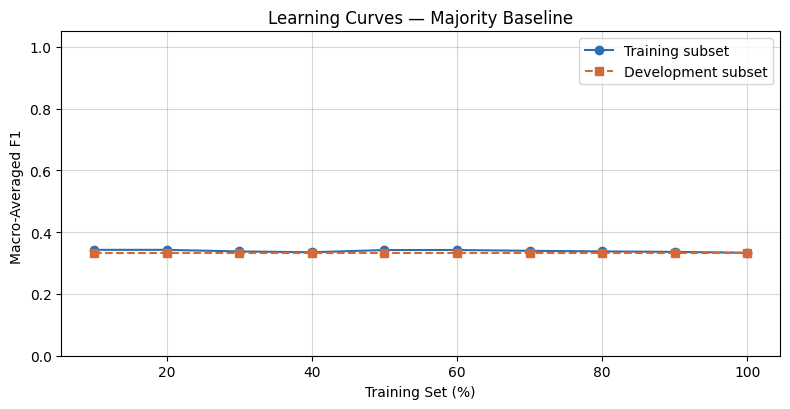

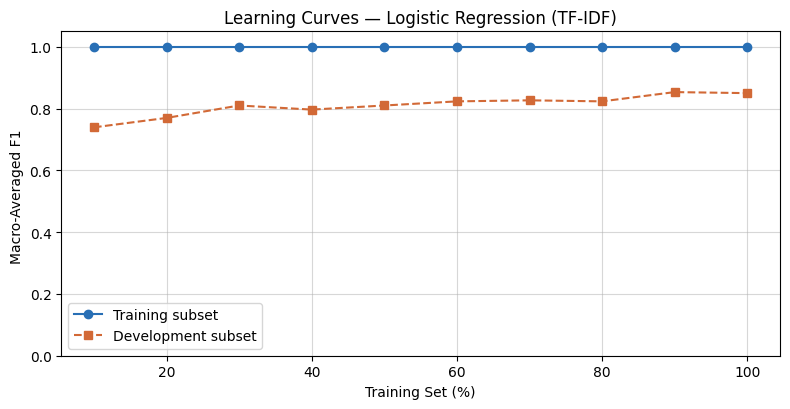

In [ ]:
fractions = np.linspace(0.1, 1.0, 10)
n_train = X_train_tfidf.shape[0]

models = {
    'Majority Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression (TF-IDF)': LogisticRegression(
        C=best_C, max_iter=1000, random_state=SEED
    ),
}

for name in models:
  train_scores, dev_scores = [], []

  for frac in fractions:
    sub_size = int(frac * n_train)
    X_sub = X_train_tfidf[:sub_size]
    y_sub = y_train[:sub_size]

    clf = (
        DummyClassifier(strategy='most_frequent')
        if 'Majority' in name
        else LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
    )
    clf.fit(X_sub, y_sub)

    train_scores.append(f1_score(y_sub, clf.predict(X_sub), average='macro'))
    dev_scores.append(f1_score(y_dev, clf.predict(X_dev_tfidf), average='macro'))

  plt.figure(figsize=(8, 4.2))
  plt.plot(
      fractions * 100,
      train_scores,
      'o-',
      color=POS,
      label='Training subset',
  )
  plt.plot(
      fractions * 100,
      dev_scores,
      's--',
      color=NEG,
      label='Development subset',
  )
  plt.title(f'Learning Curves — {name}')
  plt.xlabel('Training Set (%)')
  plt.ylabel('Macro-Averaged F1 ')
  plt.ylim(0, 1.05)
  plt.grid(True, alpha=0.5)
  plt.legend()
  plt.tight_layout()
  plt.show()